# Milestone 2: Data Processing & EDA
**AC209B** 

**Project #63**

**Group Members:** Matlin Gilman and Brianna Grissom

---

## Background

For patients hospitalized with serious mental illness (SMI), housing is not a side topic in discharge planning — it is central to whether the plan will work. Medication adherence, follow-up attendance, and the risk of returning to the ER all depend on whether the patient has a stable place to go. This is why clinical best practices for SMI discharge planning treat housing as something providers should *always* assess and document in the discharge summary. SMI is exactly the population where this should happen every time.

## Research Question

> **How consistently is housing actually mentioned in discharge summaries for patients hospitalized with serious mental illness — and do mention rates differ by race, insurance, or gender?**

## What We Mean by "Housing Mention"

Discharge summaries contain an administrative `Discharge Disposition: Home` line that records where the patient went. But "home" here is a billing label — it could mean a house, a shelter, or a car. We strip this line out and search only the **clinical narrative** — what a provider actually wrote about the patient's social situation.

## Our Approach

1. Build a 20-keyword search for housing-related language and validate it against an independent hand-labeled dataset (MIMIC-III-Labeled-SDOH).
2. Apply the validated search to MIMIC-IV-Note discharge summaries for our SMI cohort and break down the results by diagnosis and demographics.
3. (Milestone 3) Replace the keyword baseline with a fine-tuned ClinicalBERT model for context-aware detection.

## Data Sources

| Source | What It Contains |
|---|---|
| **MIMIC-IV** (structured tables) | A large, publicly available critical care database covering ~546,000 hospital admissions at Beth Israel Deaconess Medical Center (Boston) between 2008 and 2019. We use three tables: `admissions.csv` (one row per hospital stay, with race, insurance, discharge disposition, and timestamps), `patients.csv` (one row per patient, with gender and de-identified age), and `diagnoses_icd.csv` (one row per diagnosis per admission, with ICD-9 and ICD-10 codes ranked by clinical priority via `seq_num`). Access requires PhysioNet credentialing and a data use agreement. |
| **MIMIC-IV-Note** (clinical text) | A companion release to MIMIC-IV containing ~331,000 deidentified free-text discharge summaries written by clinicians. Notes are split across 7 CSV files and linked to MIMIC-IV admissions by `hadm_id` (the hospital admission ID). This is the corpus we search for housing mentions. Coverage is partial — not every MIMIC-IV admission has a corresponding note, for reasons related to the data release process rather than clinical practice. |
| **MIMIC-III-Labeled-SDOH** | A separate, smaller dataset of 1,800 clinical sentences from the earlier MIMIC-III release, hand-labeled by human annotators for the presence of social determinants of health (housing, food insecurity, substance use, etc.) and whether each mention is *adverse* (e.g., homelessness) or non-adverse. We use it solely as an independent validation set to measure the precision and recall of our keyword search before applying it to MIMIC-IV-Note. |

## Step 1: Load the Structured Tables
*Data: MIMIC-IV*

In [1]:
import os
import pandas as pd

# Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Google Colab; skipping drive.mount().")


# Load in data
base_path = '/content/drive/MyDrive/AC209b-project-data'
admissions_path = os.path.join(base_path, 'admissions-000000000000.csv')
patients_path = os.path.join(base_path, 'patients-000000000000.csv')
diagnoses_icd_path = os.path.join(base_path, 'diagnoses_icd.csv')


admissions_df = pd.read_csv(admissions_path)
patients_df = pd.read_csv(patients_path)
diagnoses_icd_df = pd.read_csv(diagnoses_icd_path)

print('Loaded files:')
print(f'  admissions_df:     {admissions_df.shape}')
print(f'  patients_df:       {patients_df.shape}')
print(f'  diagnoses_icd_df:  {diagnoses_icd_df.shape}')

Mounted at /content/drive
Loaded files:
  admissions_df:     (546028, 16)
  patients_df:       (364627, 6)
  diagnoses_icd_df:  (6364488, 5)


In [ ]:
print('admissions_df columns:')
print(admissions_df.columns.tolist())
print()

print('patients_df columns:')
print(patients_df.columns.tolist())
print()

print('diagnoses_icd_df columns:')
print(diagnoses_icd_df.columns.tolist())

admissions_df columns:
['subject_id', 'hadm_id', 'admittime', 'dischtime', 'deathtime', 'admission_type', 'admit_provider_id', 'admission_location', 'discharge_location', 'insurance', 'language', 'marital_status', 'race', 'edregtime', 'edouttime', 'hospital_expire_flag']

patients_df columns:
['subject_id', 'gender', 'anchor_age', 'anchor_year', 'anchor_year_group', 'dod']

diagnoses_icd_df columns:
['subject_id', 'hadm_id', 'seq_num', 'icd_code', 'icd_version']


Each MIMIC-IV table plays a distinct role downstream:

- **`admissions`** (one row per stay) is our unit of analysis. Race, insurance, discharge disposition, and timestamps live here.
- **`patients`** (one row per patient) supplies gender and age, joined onto admissions.
- **`diagnoses_icd`** (one row per diagnosis per admission) is how we identify SMI admissions. The `seq_num` column ranks diagnoses by clinical priority — we use `seq_num == 1` to find each admission's *primary* reason for hospitalization.

In Step 6 we bring in a fourth source — MIMIC-IV-Note — which contains the discharge summary text.

## Step 2: Build an Admission-Level Dataset
*Data: MIMIC-IV*

The structured MIMIC-IV tables come split apart. We assemble them into a single dataframe where each row is one hospital stay carrying all the patient demographics, insurance, and outcome flags we will eventually break our results down by.

In [ ]:
# Merge to create an admission-level dataset
admission_level_df = admissions_df.merge(
    patients_df,
    on='subject_id',
    how='left',
    validate='many_to_one'
 )

# Sort by subject_id
admission_level_df = admission_level_df.sort_values('subject_id').reset_index(drop=True)

# hadm_id should uniquely identify each admission row
if admission_level_df['hadm_id'].duplicated().any():
    raise ValueError('hadm_id is not unique after merge; check input data.')

print(f'admission_level_df shape: {admission_level_df.shape}')
print(f"Unique hadm_id count: {admission_level_df['hadm_id'].nunique()}")
admission_level_df.head()

In [4]:
# Create four race categories: Hispanic, White (non-Hispanic), Black (non-Hispanic), Other
def map_race(race_val):
    if pd.isna(race_val):
        return 'Other'
    r = str(race_val).upper()
    if 'HISPANIC' in r or 'LATINO' in r:
        return 'Hispanic'
    elif r.startswith('WHITE'):
        return 'White'
    elif 'BLACK' in r or 'AFRICAN AMERICAN' in r:
        return 'Black'
    else:
        return 'Other'

admission_level_df['race_category'] = admission_level_df['race'].apply(map_race)
print('Race category distribution:')
print(admission_level_df['race_category'].value_counts(dropna=False))

Race category distribution:
race_category
White       360519
Black        89057
Other        64242
Hispanic     32210
Name: count, dtype: int64


In [5]:
# Create four insurance categories: Medicaid, Medicare, Private, Other (all other)
def map_insurance(ins_val):
    if pd.isna(ins_val):
        return 'Other'
    i = str(ins_val).strip()
    if i in ('Medicaid', 'Medicare', 'Private'):
        return i
    return 'Other'

admission_level_df['insurance_category'] = admission_level_df['insurance'].apply(map_insurance)
print('Insurance category distribution:')
print(admission_level_df['insurance_category'].value_counts(dropna=False))

Insurance category distribution:
insurance_category
Medicare    244576
Private     173399
Medicaid    104229
Other        23824
Name: count, dtype: int64


In [ ]:
# Gender distribution
print('Gender distribution:')
print(admission_level_df['gender'].value_counts(dropna=False))

Gender distribution:
gender
F    284097
M    261931
Name: count, dtype: int64


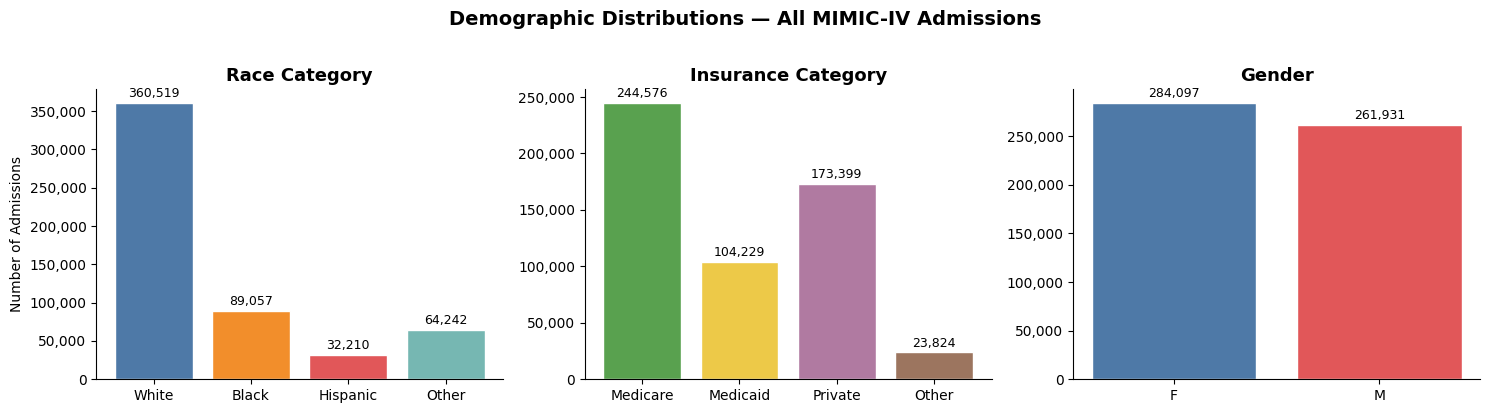

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Race
race_order = ['White', 'Black', 'Hispanic', 'Other']
race_counts = admission_level_df['race_category'].value_counts().reindex(race_order, fill_value=0)
colors_race = ['#4e79a7', '#f28e2b', '#e15759', '#76b7b2']
axes[0].bar(race_counts.index, race_counts.values, color=colors_race, edgecolor='white')
axes[0].set_title('Race Category', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Admissions')
for i, v in enumerate(race_counts.values):
    axes[0].text(i, v + race_counts.max() * 0.01, f'{v:,}', ha='center', va='bottom', fontsize=9)

# Insurance
ins_order = ['Medicare', 'Medicaid', 'Private', 'Other']
ins_counts = admission_level_df['insurance_category'].value_counts().reindex(ins_order, fill_value=0)
colors_ins = ['#59a14f', '#edc948', '#b07aa1', '#9c755f']
axes[1].bar(ins_counts.index, ins_counts.values, color=colors_ins, edgecolor='white')
axes[1].set_title('Insurance Category', fontsize=13, fontweight='bold')
for i, v in enumerate(ins_counts.values):
    axes[1].text(i, v + ins_counts.max() * 0.01, f'{v:,}', ha='center', va='bottom', fontsize=9)

# Gender
gender_counts = admission_level_df['gender'].value_counts()
colors_gender = ['#4e79a7', '#e15759']
axes[2].bar(gender_counts.index, gender_counts.values, color=colors_gender[:len(gender_counts)], edgecolor='white')
axes[2].set_title('Gender', fontsize=13, fontweight='bold')
for i, v in enumerate(gender_counts.values):
    axes[2].text(i, v + gender_counts.max() * 0.01, f'{v:,}', ha='center', va='bottom', fontsize=9)

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

fig.suptitle('Demographic Distributions — All MIMIC-IV Admissions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

These distributions describe the **full MIMIC-IV hospital population**, not our final cohort — predominantly White, mostly on Medicare. They serve as a baseline for comparison once we narrow to the SMI cohort below.

In [8]:
# Convert time-like columns in admission_level_df to datetime
time_columns = [col for col in admission_level_df.columns if 'time' in col.lower()]

if not time_columns:
    print('No time columns found in admission_level_df.')
else:
    for col in time_columns:
        admission_level_df[col] = pd.to_datetime(admission_level_df[col], errors='coerce')

In [9]:
admit_col = 'admittime'
discharge_col = 'dischtime'
death_col = 'deathtime'

# Sort chronologically within patient before computing next admission
admission_level_df = admission_level_df.sort_values(['subject_id', admit_col]).reset_index(drop=True)

# Next admission per patient
admission_level_df['next_admittime'] = admission_level_df.groupby('subject_id')[admit_col].shift(-1)
admission_level_df['days_to_next_admission'] = (
    admission_level_df['next_admittime'] - admission_level_df[discharge_col]
).dt.total_seconds() / (24 * 3600)

# In-hospital death: hospital_expire_flag == 1 OR discharge_location == "DIED"
in_hospital_death = (
    (admission_level_df['hospital_expire_flag'] == 1)
    | (admission_level_df['discharge_location'] == 'DIED')
)

admission_level_df['in_hospital_death'] = in_hospital_death

# Readmission within 30 days, excluding in-hospital deaths
admission_level_df['readmission_30day'] = (
    admission_level_df['days_to_next_admission'].between(0, 30, inclusive='both')
    & ~in_hospital_death
).astype(int)

print(f"30-day readmission rate: {admission_level_df['readmission_30day'].mean():.3f}")
print(admission_level_df['readmission_30day'].value_counts(dropna=False))

30-day readmission rate: 0.200
readmission_30day
0    436699
1    109329
Name: count, dtype: int64


In [ ]:
print(admission_level_df['in_hospital_death'].value_counts(dropna=False))

in_hospital_death
False    534000
True      12028
Name: count, dtype: int64


In [11]:
# Optional cleanup: drop helper columns used for readmission calculation
helper_cols = ['next_admittime', 'days_to_next_admission']
if (helper_cols[0] in admission_level_df.columns.to_list()) and (helper_cols[1] in admission_level_df.columns.to_list()):
    admission_level_df = admission_level_df.drop(columns=helper_cols, errors='ignore')

We compute two binary outcome variables now, before any filtering, so the same definitions apply to every admission:

- **In-hospital death** combines two MIMIC-IV signals — `hospital_expire_flag == 1` *or* `discharge_location == "DIED"` — so we don't miss deaths recorded in only one field. We exclude these admissions in Step 4.
- **30-day readmission**: another admission within 30 days of discharge, with in-hospital deaths excluded from the denominator since readmission is undefined for them.

Readmission matters here because **it is a standard healthcare quality indicator** — CMS tracks it, hospitals are scored on it — and because unstable housing is one of the strongest known drivers of psychiatric readmission. In Milestone 3 we plan to test whether housing mention is associated with 30-day readmission in our cohort.

## Step 3: Filter to the SMI Cohort
*Data: MIMIC-IV*

We want every admission in our analysis to be one where the *primary* reason for hospitalization was a serious mental illness — not an admission for something else that happens to carry a psychiatric code. We attach the first-listed ICD code to each admission and keep only those falling into our three SMI categories.

In [ ]:
first_dx = (
    diagnoses_icd_df.loc[diagnoses_icd_df['seq_num'] == 1, ['hadm_id', 'icd_code', 'icd_version']]
    .drop_duplicates(subset='hadm_id', keep='first')
    .rename(columns={'icd_code': 'first_icd_code', 'icd_version': 'first_icd_version'})
)

# Safe re-run: remove prior merged columns if they already exist
admission_level_df = admission_level_df.drop(columns=['first_icd_code', 'first_icd_version'], errors='ignore')

admission_level_df = admission_level_df.merge(first_dx, on='hadm_id', how='left')

print(f"Rows in admission_level_df: {len(admission_level_df):,}")
print(f"Rows with first-listed ICD: {admission_level_df['first_icd_code'].notna().sum():,}")
admission_level_df[['hadm_id', 'first_icd_code', 'first_icd_version']].head()

We use the **first-listed ICD code** (`seq_num == 1`), which represents the principal reason the patient was hospitalized. Using the first-listed code rather than any-position diagnosis is essential: a patient admitted for a hip fracture who happens to also carry a depression diagnosis is not who we want to study. We are looking for patients hospitalized *for* their psychiatric illness, because those are the discharge plans where housing should be most salient.

In [13]:
# Restrict to admissions with target first-listed ICD diagnoses
required_cols = {'first_icd_code', 'first_icd_version'}
missing_cols = required_cols - set(admission_level_df.columns)
if missing_cols:
    raise KeyError(f"Missing columns in admission_level_df: {missing_cols}")

code = admission_level_df['first_icd_code'].astype(str).str.upper().str.replace('.', '', regex=False).str.strip()
version_num = pd.to_numeric(admission_level_df['first_icd_version'], errors='coerce').astype('Int64')

is_icd9 = version_num == 9
is_icd10 = version_num == 10

# Schizophrenia: ICD-10 F20.x/F25.x; ICD-9 295.xx
admission_level_df['schizophrenia'] = (
    (is_icd10 & (code.str.startswith('F20') | code.str.startswith('F25')))
    | (is_icd9 & code.str.startswith('295'))
).astype(int)

# Bipolar disorder: ICD-10 F30.x/F31.x; ICD-9 296.0x, 296.1x, 296.4x, 296.5x, 296.6x, 296.7, 296.8x
admission_level_df['bipolar_disorder'] = (
    (is_icd10 & (code.str.startswith('F30') | code.str.startswith('F31')))
    | (
        is_icd9
        & (
            code.str.startswith('2960')
            | code.str.startswith('2961')
            | code.str.startswith('2964')
            | code.str.startswith('2965')
            | code.str.startswith('2966')
            | (code == '2967')
            | code.str.startswith('2968')
        )
    )
).astype(int)

# Major depressive disorder: ICD-10 F32.2, F32.3, F33.x; ICD-9 296.23, 296.24, 296.3x
admission_level_df['major_depressive_disorder'] = (
    (
        is_icd10
        & (
            code.isin(['F322', 'F323'])
            | code.str.startswith('F33')
        )
    )
    | (
        is_icd9
        & (
            code.isin(['29623', '29624'])
            | code.str.startswith('2963')
        )
    )
).astype(int)

# Keep admissions where at least one target diagnosis is present
psychiatric_dx_mask = (
    (admission_level_df['schizophrenia'] == 1)
    | (admission_level_df['bipolar_disorder'] == 1)
    | (admission_level_df['major_depressive_disorder'] == 1)
)

admissions_before = len(admission_level_df)
patients_before = len(admission_level_df['subject_id'].unique())

df_smi = admission_level_df.loc[psychiatric_dx_mask].copy()

admissions_after = len(df_smi)
patients_after = len(df_smi['subject_id'].unique())


print(f'Number of admissions before restriction: {admissions_before:,}')
print(f'Number of admissions after restriction:  {admissions_after:,}')
print(f'Kept: {admissions_after / admissions_before:.2%}')
print()

print(f'Number of patients before restriction: {patients_before:,}')
print(f'Number of patients after restriction:  {patients_after:,}')
print(f'Kept: {patients_after / patients_before:.2%}')
print()

print('Indicator counts in restricted dataset:')
print(df_smi[['schizophrenia', 'bipolar_disorder', 'major_depressive_disorder']].sum())

Number of admissions before restriction: 546,028
Number of admissions after restriction:  10,168
Kept: 1.86%

Number of patients before restriction: 223,452
Number of patients after restriction:  5,691
Kept: 2.55%

Indicator counts in restricted dataset:
schizophrenia                3396
bipolar_disorder             3734
major_depressive_disorder    3038
dtype: int64


We kept admissions whose first-listed ICD code falls into one of three SMI categories:

| Condition | ICD-10 Codes | ICD-9 Codes |
|---|---|---|
| **Schizophrenia** | F20.x, F25.x | 295.xx |
| **Bipolar disorder** | F30.x, F31.x | 296.0x, 296.1x, 296.4x–296.8x |
| **Major depressive disorder (severe/recurrent)** | F32.2, F32.3, F33.x | 296.23, 296.24, 296.3x |

For MDD we deliberately include only severe and recurrent episodes — not mild or moderate single episodes — because patients hospitalized for severe or recurrent depression face the same housing-related challenges as those with schizophrenia or bipolar disorder. We define each condition in both ICD-9 and ICD-10 because MIMIC-IV spans the U.S. coding transition (October 2015). This filter drops about 98% of MIMIC-IV admissions and produces our working SMI cohort.

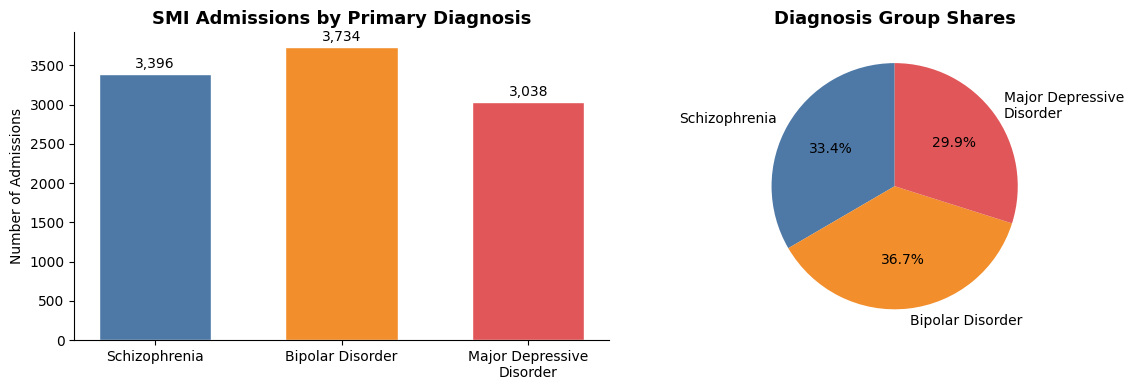


Total SMI admissions: 10,168  |  Unique patients: 5,691


In [14]:
# Visualize SMI cohort composition
dx_labels = ['Schizophrenia', 'Bipolar Disorder', 'Major Depressive\nDisorder']
dx_vals = [
    int(df_smi['schizophrenia'].sum()),
    int(df_smi['bipolar_disorder'].sum()),
    int(df_smi['major_depressive_disorder'].sum()),
]
colors_dx = ['#4e79a7', '#f28e2b', '#e15759']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
bars = axes[0].bar(dx_labels, dx_vals, color=colors_dx, edgecolor='white', width=0.6)
axes[0].set_title('SMI Admissions by Primary Diagnosis', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Admissions')
for bar, v in zip(bars, dx_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + max(dx_vals)*0.01,
                 f'{v:,}', ha='center', va='bottom', fontsize=10)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Pie chart
axes[1].pie(dx_vals, labels=dx_labels, colors=colors_dx, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 10})
axes[1].set_title('Diagnosis Group Shares', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print(f'\nTotal SMI admissions: {len(df_smi):,}  |  Unique patients: {df_smi["subject_id"].nunique():,}')

## Step 4: Remove Non-Community Discharges
*Data: MIMIC-IV*

Not every admission ends with the patient going home. Some are transferred to other facilities, some leave against medical advice, and some die during the stay. None of these are situations where we would expect a clinician to document housing as part of a community discharge plan, and including them would dilute our denominator with admissions where housing documentation simply isn't applicable.

In [15]:
# Remove transfers, against-advice discharges, and in-hospital deaths
rows_before = len(df_smi)

# Transfers and against-advice
to_remove = ['ACUTE HOSPITAL', 'OTHER FACILITY', 'PSYCH FACILITY', 'AGAINST ADVICE']
mask_transfer = df_smi['discharge_location'].isin(to_remove)
n_transfers = int(mask_transfer.sum())

# In-hospital deaths (among non-transferred)
mask_death = (~mask_transfer) & (df_smi['in_hospital_death'] == 1)
n_deaths = int(mask_death.sum())

# Remove both
df_smi = df_smi.loc[~mask_transfer & ~mask_death].copy()
rows_after = len(df_smi)

print(f'Rows before:                   {rows_before:,}')
print(f'  Transfers/against advice:    -{n_transfers:,}')
print(f'  In-hospital deaths:          -{n_deaths:,}')
print(f'Rows after exclusions:          {rows_after:,}')

Rows before:                   10,168
  Transfers/against advice:    -587
  In-hospital deaths:          -1
Rows after exclusions:          9,580


We removed three classes of admissions:

- **Transfers** to acute hospitals, other facilities, or psychiatric facilities — the discharge summary in these cases is an inter-facility handoff, not a community discharge plan.
- **Against-advice** discharges — the patient left before a formal discharge plan was completed.
- **In-hospital deaths** — no community discharge plan exists.

Every remaining admission now represents a patient discharged to a community setting: the population for whom housing documentation is clinically expected.

## Step 5: Validate the Keyword Search
*Data: **MIMIC-III-Labeled-SDOH** (a separate, independent dataset — not MIMIC-IV)*

**A brief detour from our cohort.** Before applying our keyword search to MIMIC-IV discharge summaries, we need to know how well it actually works. To answer that, we step away from MIMIC-IV entirely and evaluate the search against **MIMIC-III-Labeled-SDOH** — a completely separate dataset of clinical sentences from an earlier MIMIC release that human annotators have already labeled for social determinants of health. Because it is unrelated to our MIMIC-IV cohort, it gives us a fair external check on the keyword tool itself, after which we will return to MIMIC-IV in Step 6.

The keywords cover obvious terms (`homeless`, `shelter`, `eviction`) and indirect phrases (`couch surfing`, `no fixed address`, `lives with`).

In [16]:
# Build and evaluate housing keyword search using MIMIC-III-Labeled-SDOH
import re
from pathlib import Path


round1 = pd.read_csv('/content/drive/MyDrive/AC209b-project-data/SyntheticSentences_Round1.csv')
round2 = pd.read_csv('/content/drive/MyDrive/AC209b-project-data/SyntheticSentences_Round2.csv')
labeled_sdoh = pd.concat([round1, round2], ignore_index=True)
print(f'Merged labeled dataset shape: {labeled_sdoh.shape}')

adverse_col = 'adverse'

HOUSING_PATTERNS = [
    r'\bhousing\b', r'\bhoused\b', r'\bunhoused\b', r'\bhomeless\b',
    r'\bshelter\b', r'\btransitional housing\b', r'\bhalfway house\b', r'\bgroup home\b',
    r'\bstable housing\b', r'\bhousing instability\b', r'\bhousing insecure\b',
    r'\beviction\b', r'\bevicted\b', r'\bno fixed address\b', r'\bno permanent address\b',
    r'\bcouch[- ]surf\w*\b', r'\btemporary housing\b', r'\bboard and care\b',
    r'\blives with\b', r'\bapartment\b',
]
HOUSING_REGEX = re.compile('|'.join(HOUSING_PATTERNS), flags=re.IGNORECASE)

def housing_keyword_search(text):
    if pd.isna(text):
        return 0
    return int(bool(HOUSING_REGEX.search(str(text))))

keyword_module = Path('housing_keyword_search.py')
keyword_module.write_text(
    "import re\n\n"
    "HOUSING_PATTERNS = [\n"
    "    r'\\bhousing\\b', r'\\bhoused\\b', r'\\bunhoused\\b', r'\\bhomeless\\b',\n"
    "    r'\\bshelter\\b', r'\\btransitional housing\\b', r'\\bhalfway house\\b', r'\\bgroup home\\b',\n"
    "    r'\\bstable housing\\b', r'\\bhousing instability\\b', r'\\bhousing insecure\\b',\n"
    "    r'\\beviction\\b', r'\\bevicted\\b', r'\\bno fixed address\\b', r'\\bno permanent address\\b',\n"
    "    r'\\bcouch[- ]surf\\w*\\b', r'\\btemporary housing\\b', r'\\bboard and care\\b',\n"
    "    r'\\blives with\\b', r'\\bapartment\\b',\n"
    "]\n\n"
    "HOUSING_REGEX = re.compile('|'.join(HOUSING_PATTERNS), flags=re.IGNORECASE)\n\n"
    "def housing_keyword_search(text):\n"
    "    if text is None:\n"
    "        return 0\n"
    "    text = str(text)\n"
    "    if text.strip() == '':\n"
    "        return 0\n"
    "    return int(bool(HOUSING_REGEX.search(text)))\n"
 )
print(f'Saved reusable keyword code to: {keyword_module.resolve()}')

y_true = labeled_sdoh['label'].astype(str).str.strip().str.upper().eq('HOUSING').astype(int)
y_pred = labeled_sdoh['text'].apply(housing_keyword_search).astype(int)

tp = int(((y_pred == 1) & (y_true == 1)).sum())
tn = int(((y_pred == 0) & (y_true == 0)).sum())
fp = int(((y_pred == 1) & (y_true == 0)).sum())
fn = int(((y_pred == 0) & (y_true == 1)).sum())

precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

print('\nOverall housing detection performance:')
print(f'  TP: {tp}')
print(f'  TN: {tn}')
print(f'  FP: {fp}')
print(f'  FN: {fn}')
print(f'  Precision: {precision:.3f}')
print(f'  Recall:    {recall:.3f}')
print(f'  F1:        {f1:.3f}')

adverse_norm = labeled_sdoh['adverse'].astype(str).str.strip().str.lower()
true_housing = y_true == 1
adverse_housing = true_housing & adverse_norm.eq('adverse')
nonadverse_housing = true_housing & adverse_norm.isin(['non-adverse', 'nonadverse'])

adverse_recall = y_pred[adverse_housing].mean() if adverse_housing.sum() > 0 else float('nan')
nonadverse_recall = y_pred[nonadverse_housing].mean() if nonadverse_housing.sum() > 0 else float('nan')

print('\nRecall within true HOUSING rows by adverse status:')
print(f'  Adverse recall:     {adverse_recall:.3f} (n={int(adverse_housing.sum())})')
print(f'  Non-adverse recall: {nonadverse_recall:.3f} (n={int(nonadverse_housing.sum())})')

labeled_sdoh = labeled_sdoh.copy()
labeled_sdoh['housing_label_bin'] = y_true
labeled_sdoh['housing_keyword_pred'] = y_pred
keyword_eval = pd.DataFrame([{
    'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn,
    'precision': precision, 'recall': recall, 'f1': f1
}])

Merged labeled dataset shape: (1800, 3)
Saved reusable keyword code to: /content/housing_keyword_search.py

Overall housing detection performance:
  TP: 78
  TN: 1574
  FP: 26
  FN: 122
  Precision: 0.750
  Recall:    0.390
  F1:        0.513

Recall within true HOUSING rows by adverse status:
  Adverse recall:     0.390 (n=200)
  Non-adverse recall: nan (n=0)


The validation results tell us two things about the keyword baseline:

- **Precision is good (≈ 0.75).** When the search flags a sentence as being about housing, it is right about three quarters of the time.
- **Recall is poor (≈ 0.39).** The search catches only about four in ten true housing sentences. The other 60% use phrasing the keyword list doesn't cover — a clinician writing *"patient has nowhere to go after discharge"* will not be flagged by the word `homeless`.

This asymmetry matters for how we interpret our final results. Because recall is low, **any housing mention rate we report on the SMI cohort is a lower bound on the true rate**. If we find that 50% of notes mention housing, the real fraction with *any* housing discussion is almost certainly higher. The keyword search is our **Milestone 2 baseline**; in Milestone 3 a fine-tuned ClinicalBERT model will replace it.

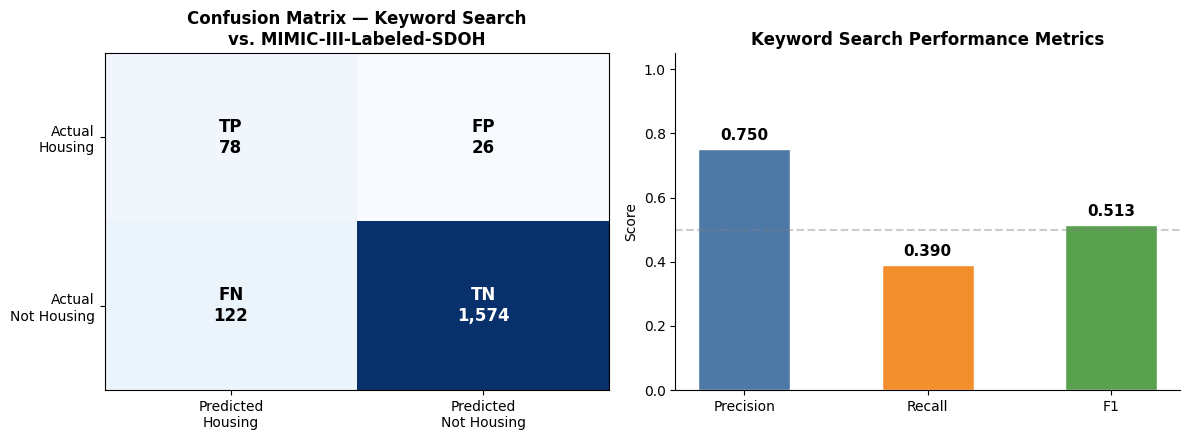

In [17]:
# Visualize keyword search performance
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion matrix heatmap
cm = [[tp, fp], [fn, tn]]
cm_labels = [['TP', 'FP'], ['FN', 'TN']]
im = axes[0].imshow(cm, cmap='Blues', aspect='auto')
axes[0].set_xticks([0, 1])
axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Predicted\nHousing', 'Predicted\nNot Housing'], fontsize=10)
axes[0].set_yticklabels(['Actual\nHousing', 'Actual\nNot Housing'], fontsize=10)
for i in range(2):
    for j in range(2):
        val = cm[i][j]
        axes[0].text(j, i, f'{cm_labels[i][j]}\n{val:,}', ha='center', va='center',
                     fontsize=12, fontweight='bold',
                     color='white' if val > max(tp, tn)*0.5 else 'black')
axes[0].set_title('Confusion Matrix — Keyword Search\nvs. MIMIC-III-Labeled-SDOH', fontsize=12, fontweight='bold')

# Precision / Recall / F1 bar chart
metrics = ['Precision', 'Recall', 'F1']
values = [precision, recall, f1]
bar_colors = ['#4e79a7', '#f28e2b', '#59a14f']
bars = axes[1].bar(metrics, values, color=bar_colors, edgecolor='white', width=0.5)
axes[1].set_ylim(0, 1.05)
axes[1].set_ylabel('Score')
axes[1].set_title('Keyword Search Performance Metrics', fontsize=12, fontweight='bold')
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 0.02, f'{v:.3f}',
                 ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].axhline(y=0.5, color='gray', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## Step 6: Attach Discharge Notes and Clean the Text
*Data: MIMIC-IV (structured)  +  **MIMIC-IV-Note** (clinical text)*

We now return to our MIMIC-IV cohort. Up to this point we have used only the structured tables — admissions, patients, diagnoses. The actual discharge summary text lives in **MIMIC-IV-Note**, which is a *separate* data release from MIMIC-IV: same hospital, same patients, but published as its own dataset of free-text notes. We load those notes and join them onto our SMI cohort by `hadm_id` (the hospital admission ID, which is the link between the two releases), then clean one specific artifact out of the text before searching it.

In [18]:
# Load discharge notes (mimic-iv notes) — 7 files
discharge_files = [
    f'discharge-00000000000{i}.csv' for i in range(7)
]

discharge_dfs = []
for f in discharge_files:
    df = pd.read_csv(os.path.join(base_path, f))
    discharge_dfs.append(df)

discharge = pd.concat(discharge_dfs, ignore_index=True)
print(f"Discharge notes shape: {discharge.shape}")
print(f"Discharge columns: {list(discharge.columns)}")

Discharge notes shape: (331793, 8)
Discharge columns: ['note_id', 'subject_id', 'hadm_id', 'note_type', 'note_seq', 'charttime', 'storetime', 'text']


In [19]:
# Add discharge note text to df_smi by hadm_id (merge ALL notes, including missing)
notes_by_hadm = (
    discharge[["hadm_id", "text"]]
    .dropna(subset=["hadm_id"])
    .drop_duplicates(subset=["hadm_id"], keep="first")
    .set_index("hadm_id")["text"]
)

df_smi["discharge_text"] = df_smi["hadm_id"].map(notes_by_hadm)

print("Rows in df_smi:", len(df_smi))
print("Rows with matched discharge note:", df_smi["discharge_text"].notna().sum())
print("Rows without discharge note:", df_smi["discharge_text"].isna().sum())

Rows in df_smi: 9580
Rows with matched discharge note: 3808
Rows without discharge note: 5772


Every SMI admission now carries either a discharge note or a missing value. We will drop the missing rows in Step 7, but only after one more cleaning step on the notes that *do* exist.

In [20]:
# Remove only the "Discharge Disposition:" line + one non-heading line from discharge_text
import re

if 'discharge_text' not in df_smi.columns:
    raise KeyError("Column `discharge_text` not found in df_smi.")

# Removes:
#   Discharge Disposition: <...>
#   <one following line if it is not a section header like "Discharge Diagnosis:">
dispo_block_pattern = (
    r'^[ \t]*Discharge[ \t]+Disposition:[^\r\n]*\r?\n'
    r'(?:[ \t]*(?![A-Za-z][^:\r\n]*:)[^\r\n]*\r?\n?)?'
)
dispo_flags = re.IGNORECASE | re.MULTILINE

df_smi = df_smi.copy()

# Coerce placeholder strings to true missing values so they remain empty (not literal "nan")
discharge_text_str = df_smi['discharge_text'].astype('string').str.strip()
missing_like = discharge_text_str.isna() | discharge_text_str.str.lower().isin(['', 'nan', 'none', 'null'])
df_smi.loc[missing_like, 'discharge_text'] = pd.NA

# Store removed text in a separate variable/column (preserves NA rows as NA)
discharge_disposition_removed = df_smi['discharge_text'].str.extract(
    f'({dispo_block_pattern})',
    flags=dispo_flags,
    expand=False
)
df_smi['discharge_disposition_removed'] = discharge_disposition_removed

# Remove that section from discharge_text (keep downstream headers like "Discharge Diagnosis:")
df_smi['discharge_text'] = df_smi['discharge_text'].str.replace(
    dispo_block_pattern,
    '',
    regex=True,
    flags=dispo_flags
)

print('Discharge Disposition cleanup complete:')
print(f"  Rows with removed section: {df_smi['discharge_disposition_removed'].notna().sum():,}")
print(f"  Rows with missing/empty discharge_text: {df_smi['discharge_text'].isna().sum():,}")
print(f"  Total rows: {len(df_smi):,}")

Discharge Disposition cleanup complete:
  Rows with removed section: 3,799
  Rows with missing/empty discharge_text: 5,772
  Total rows: 9,580


**Why strip the disposition line.** Nearly every discharge summary contains an administrative line like:

> *Discharge Disposition: Home*

The word "home" here is a billing label for where the patient went, not a clinical assessment of their housing. If we left it in, our keyword search would flag almost every note as mentioning housing — and every flag would be meaningless. Stripping it ensures that a keyword hit reflects something a clinician actually *wrote* about the patient's social situation. We save the removed text in `discharge_disposition_removed` so we can audit what was stripped.

## Step 7: Finalize the Cohort and Apply the Keyword Search
*Data: MIMIC-IV  +  MIMIC-IV-Note*

We now have structured MIMIC-IV data merged with cleaned MIMIC-IV-Note text. This step drops admissions without a discharge note and runs the keyword search — validated in Step 5 against MIMIC-III-Labeled-SDOH — across every remaining note to produce our primary outcome variable, `housing_mention`.

In [21]:
# Finalize cohort: drop admissions without discharge notes, then apply keyword search

# Ensure keyword regex/function are available
if 'HOUSING_REGEX' not in globals():
    import re
    HOUSING_PATTERNS = [
        r'\bhousing\b', r'\bhoused\b', r'\bunhoused\b', r'\bhomeless\b',
        r'\bshelter\b', r'\btransitional housing\b', r'\bhalfway house\b', r'\bgroup home\b',
        r'\bstable housing\b', r'\bhousing instability\b', r'\bhousing insecure\b',
        r'\beviction\b', r'\bevicted\b', r'\bno fixed address\b', r'\bno permanent address\b',
        r'\bcouch[- ]surf\w*\b', r'\btemporary housing\b', r'\bboard and care\b',
        r'\blives with\b', r'\bapartment\b',
    ]
    HOUSING_REGEX = re.compile('|'.join(HOUSING_PATTERNS), flags=re.IGNORECASE)

if 'housing_keyword_search' not in globals():
    def housing_keyword_search(text):
        if pd.isna(text):
            return 0
        text = str(text)
        if text.strip() == '':
            return 0
        return int(bool(HOUSING_REGEX.search(text)))

# Normalize placeholder strings to true missing values
df_smi_temp = df_smi.copy()
discharge_text_str = df_smi_temp['discharge_text'].astype('string').str.strip()
missing_like = discharge_text_str.isna() | discharge_text_str.str.lower().isin(['', 'nan', 'none', 'null'])
df_smi_temp.loc[missing_like, 'discharge_text'] = pd.NA

has_discharge_text = df_smi_temp['discharge_text'].notna()

# Report discharge summary availability in SMI cohort
n_with_summary = int(has_discharge_text.sum())
n_without_summary = int((~has_discharge_text).sum())
n_total_smi = len(df_smi_temp)

print('Discharge summary availability in SMI cohort:')
print(f'  With discharge summary:    {n_with_summary:,} ({n_with_summary / n_total_smi:.2%})')
print(f'  Without discharge summary: {n_without_summary:,} ({n_without_summary / n_total_smi:.2%})')
print(f'  Total:                     {n_total_smi:,}')

# Drop admissions without discharge summaries → this creates df_final
df_final = df_smi_temp.loc[has_discharge_text].copy()
print(f'\nDropped {n_without_summary:,} admissions without discharge summaries.')
print(f'Final cohort size: {len(df_final):,} admissions, {df_final["subject_id"].nunique():,} patients')

# Apply housing keyword search to all rows in final cohort
df_final['housing_mention'] = (
    df_final['discharge_text']
    .apply(housing_keyword_search)
    .astype(int)
    .map({1: 'yes', 0: 'no'})
)

n_yes = int((df_final['housing_mention'] == 'yes').sum())
n_no = int((df_final['housing_mention'] == 'no').sum())
n_total = len(df_final)

print(f'\nHousing mention in final cohort:')
print(f'  yes: {n_yes:,} ({n_yes / n_total:.2%})')
print(f'  no:  {n_no:,} ({n_no / n_total:.2%})')

Discharge summary availability in SMI cohort:
  With discharge summary:    3,808 (39.75%)
  Without discharge summary: 5,772 (60.25%)
  Total:                     9,580

Dropped 5,772 admissions without discharge summaries.
Final cohort size: 3,808 admissions, 2,859 patients

Housing mention in final cohort:
  yes: 1,940 (50.95%)
  no:  1,868 (49.05%)


We drop admissions without a matched discharge note, since we cannot search text that does not exist. **This is safe** because whether a note appears in MIMIC-IV-Note is determined by the data release process, not by the patient or the care delivered — missing notes are missing for engineering reasons, not clinical ones, so dropping them does not bias our housing documentation rate. Every remaining admission has a real discharge summary and a `housing_mention` label, our primary outcome variable.

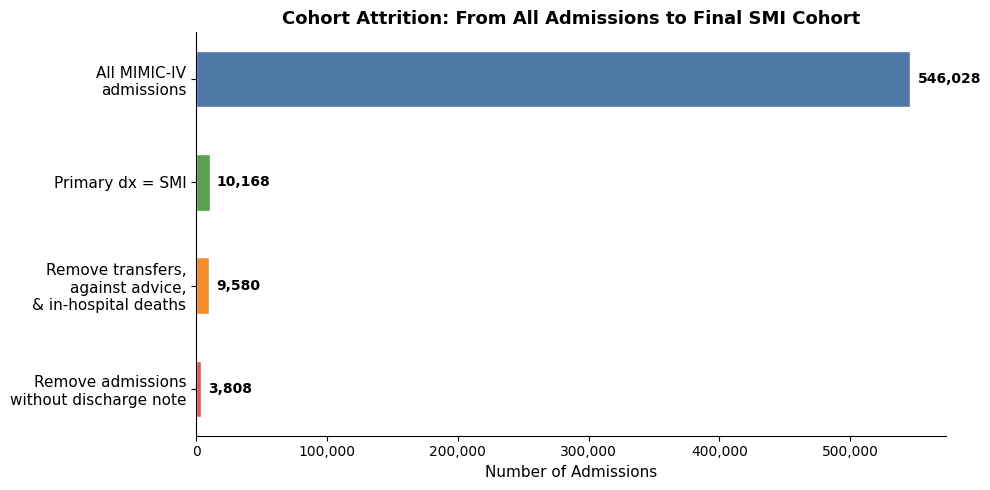

In [22]:
# Cohort attrition summary — track how the cohort narrows at each step
_smi_mask = (
    (admission_level_df['schizophrenia'] == 1)
    | (admission_level_df['bipolar_disorder'] == 1)
    | (admission_level_df['major_depressive_disorder'] == 1)
) if 'schizophrenia' in admission_level_df.columns else pd.Series([False]*len(admission_level_df))
_smi_df = admission_level_df.loc[_smi_mask]
_after_exclusions = _smi_df.loc[
    ~_smi_df['discharge_location'].isin(['ACUTE HOSPITAL', 'OTHER FACILITY', 'PSYCH FACILITY', 'AGAINST ADVICE'])
    & (_smi_df['in_hospital_death'] == 0)
]

attrition_labels = [
    'All MIMIC-IV\nadmissions',
    'Primary dx = SMI',
    'Remove transfers,\nagainst advice,\n& in-hospital deaths',
    'Remove admissions\nwithout discharge note',
]
attrition_counts = [
    len(admission_level_df),
    len(_smi_df),
    len(_after_exclusions),
    len(df_final),
]

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = ['#4e79a7', '#59a14f', '#f28e2b', '#e15759']
bars = ax.barh(range(len(attrition_labels)), attrition_counts, color=bar_colors, edgecolor='white', height=0.55)
ax.set_yticks(range(len(attrition_labels)))
ax.set_yticklabels(attrition_labels, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel('Number of Admissions', fontsize=11)
ax.set_title('Cohort Attrition: From All Admissions to Final SMI Cohort', fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{int(x):,}'))

for bar, v in zip(bars, attrition_counts):
    ax.text(v + max(attrition_counts)*0.01, bar.get_y() + bar.get_height()/2,
            f'{v:,}', ha='left', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

The funnel above tells the cohort story in one image. We start with the full hospital population (~546k admissions), narrow to the small fraction whose primary reason for hospitalization was an SMI diagnosis (10,168), exclude transfers and other non-community discharges (9,580), and finally drop admissions without a matched discharge note. What remains — **3,808 admissions across 2,859 patients** — is the set of SMI hospital stays where we can actually answer our research question.

## Step 8: Results — Housing Documentation in the SMI Cohort
*Data: MIMIC-IV  +  MIMIC-IV-Note*

We now examine the final cohort: who these patients are, and how often housing appears in their discharge summaries — overall and broken down by diagnosis, race, insurance, gender, and 30-day readmission status.

In [23]:
# Final cohort report for df_final
import numpy as np

report_df = df_final.copy()

# Use one row per admission if hadm_id is available
if 'hadm_id' in report_df.columns:
    report_df = report_df.drop_duplicates(subset='hadm_id', keep='first').copy()

n_admissions = len(report_df)
n_patients = report_df['subject_id'].nunique() if 'subject_id' in report_df.columns else float('nan')

def count_share_table(df, column, label_order=None, value_map=None, include_na=False):
    s = df[column].copy()
    if value_map is not None:
        s = s.map(value_map).fillna(s)
    if include_na:
        s = s.fillna('Missing')
    counts = s.value_counts(dropna=not include_na)
    if label_order is not None:
        counts = counts.reindex(label_order, fill_value=0)
    out = counts.rename('n').to_frame()
    out['share'] = (out['n'] / len(df)).round(4)
    return out

def housing_by_group(df, column, label_order=None, value_map=None):
    s = df[column].copy()
    if value_map is not None:
        s = s.map(value_map).fillna(s)
    groups = label_order if label_order else s.unique()
    for grp in groups:
        subset = df.loc[s == grp]
        n_grp = len(subset)
        if n_grp == 0:
            continue
        n_yes = int((subset['housing_mention'] == 'yes').sum())
        n_no = int((subset['housing_mention'] == 'no').sum())
        print(f'  {grp} (n={n_grp:,}):  yes = {n_yes:,} ({n_yes/n_grp:.2%}),  no = {n_no:,} ({n_no/n_grp:.2%})')

# ============================================================
# SECTION 1: COHORT DESCRIPTION
# ============================================================
print('='*60)
print('FINAL COHORT REPORT')
print('='*60)
print()
print('SECTION 1: COHORT DESCRIPTION')
print('-'*60)
print(f'  Patients:   {n_patients:,}')
print(f'  Admissions: {n_admissions:,}')

dx_cols = ['schizophrenia', 'bipolar_disorder', 'major_depressive_disorder']
dx_counts = report_df[dx_cols].sum().astype(int).rename('n').to_frame()
dx_counts['share'] = (dx_counts['n'] / n_admissions).round(4)
print('\n--- Admissions by primary diagnosis group ---')
print(dx_counts)

print('\n--- Admissions by race ---')
print(count_share_table(report_df, 'race_category',
                        label_order=['Hispanic', 'White', 'Black', 'Other']))

print('\n--- Admissions by insurance ---')
print(count_share_table(report_df, 'insurance_category',
                        label_order=['Medicaid', 'Medicare', 'Private', 'Other']))

print('\n--- Admissions by gender ---')
print(count_share_table(report_df, 'gender'))

readmit_tbl = count_share_table(
    report_df,
    'readmission_30day',
    label_order=['Yes', 'No'],
    value_map={1: 'Yes', 0: 'No'},
)
print('\n--- Admissions by 30-day readmission ---')
print(readmit_tbl)

# ============================================================
# SECTION 2: HOUSING MENTION FINDINGS
# ============================================================

def housing_crosstab(df, column, label_order=None, value_map=None):
    """Build a DataFrame: rows = group levels, cols = n, housing_yes, pct_yes, housing_no, pct_no."""
    s = df[column].copy()
    if value_map is not None:
        s = s.map(value_map).fillna(s)
    groups = label_order if label_order else sorted(s.unique())
    rows = []
    for grp in groups:
        mask = s == grp
        n_grp = int(mask.sum())
        if n_grp == 0:
            rows.append([grp, 0, 0, 0.0, 0, 0.0])
            continue
        n_yes = int((df.loc[mask, 'housing_mention'] == 'yes').sum())
        n_no  = n_grp - n_yes
        rows.append([grp, n_grp, n_yes, n_yes / n_grp, n_no, n_no / n_grp])
    out = pd.DataFrame(rows, columns=['group', 'n', 'housing_yes', 'pct_yes', 'housing_no', 'pct_no'])
    out['pct_yes'] = out['pct_yes'].map('{:.1%}'.format)
    out['pct_no']  = out['pct_no'].map('{:.1%}'.format)
    return out.set_index('group')

print()
print('SECTION 2: HOUSING MENTION FINDINGS')
print('='*60)

# Overall
n_yes_all = int((report_df['housing_mention'] == 'yes').sum())
n_no_all  = int((report_df['housing_mention'] == 'no').sum())
print(f'\n  Overall:  yes = {n_yes_all:,} ({n_yes_all/n_admissions:.1%}),  no = {n_no_all:,} ({n_no_all/n_admissions:.1%})')

# By primary diagnosis (indicator columns, not a single column)
print('\n--- By primary diagnosis ---')
dx_rows = []
for dx in dx_cols:
    subset = report_df.loc[report_df[dx] == 1]
    n_dx = len(subset)
    n_y = int((subset['housing_mention'] == 'yes').sum())
    n_n = n_dx - n_y
    dx_rows.append([dx, n_dx, n_y, n_y / n_dx if n_dx else 0, n_n, n_n / n_dx if n_dx else 0])
dx_tbl = pd.DataFrame(dx_rows, columns=['diagnosis', 'n', 'housing_yes', 'pct_yes', 'housing_no', 'pct_no'])
dx_tbl['pct_yes'] = dx_tbl['pct_yes'].map('{:.1%}'.format)
dx_tbl['pct_no']  = dx_tbl['pct_no'].map('{:.1%}'.format)
print(dx_tbl.set_index('diagnosis').to_string())

print('\n--- By race ---')
print(housing_crosstab(report_df, 'race_category',
                       label_order=['Hispanic', 'White', 'Black', 'Other']).to_string())

print('\n--- By insurance ---')
print(housing_crosstab(report_df, 'insurance_category',
                       label_order=['Medicaid', 'Medicare', 'Private', 'Other']).to_string())

print('\n--- By gender ---')
print(housing_crosstab(report_df, 'gender').to_string())

print('\n--- By 30-day readmission ---')
print(housing_crosstab(report_df, 'readmission_30day',
                       label_order=['Yes', 'No'],
                       value_map={1: 'Yes', 0: 'No'}).to_string())

# Token counts
report_df['n_tokens'] = report_df['discharge_text'].astype(str).str.split().apply(len)
tokens_yes = report_df.loc[report_df['housing_mention'] == 'yes', 'n_tokens']
tokens_no  = report_df.loc[report_df['housing_mention'] == 'no',  'n_tokens']

print('\n--- Discharge summary token count ---')
print(f'  With housing mention:    mean = {tokens_yes.mean():,.1f},  SD = {tokens_yes.std():,.1f}  (n = {len(tokens_yes):,})')
print(f'  Without housing mention: mean = {tokens_no.mean():,.1f},  SD = {tokens_no.std():,.1f}  (n = {len(tokens_no):,})')

FINAL COHORT REPORT

SECTION 1: COHORT DESCRIPTION
------------------------------------------------------------
  Patients:   2,859
  Admissions: 3,808

--- Admissions by primary diagnosis group ---
                              n   share
schizophrenia              1149  0.3017
bipolar_disorder           1195  0.3138
major_depressive_disorder  1464  0.3845

--- Admissions by race ---
                  n   share
race_category              
Hispanic        241  0.0633
White          2350  0.6171
Black           754  0.1980
Other           463  0.1216

--- Admissions by insurance ---
                       n   share
insurance_category              
Medicaid             836  0.2195
Medicare            1369  0.3595
Private             1229  0.3227
Other                374  0.0982

--- Admissions by gender ---
           n   share
gender              
F       1941  0.5097
M       1867  0.4903

--- Admissions by 30-day readmission ---
                      n   share
readmission_30day         

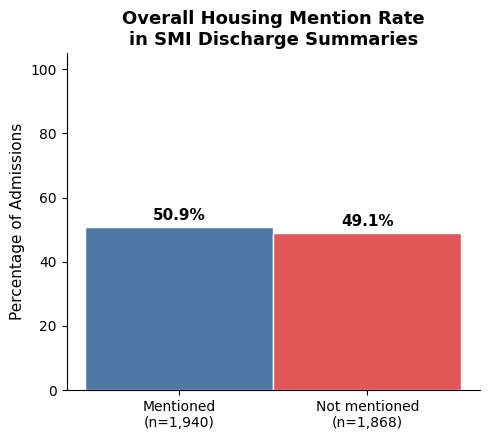

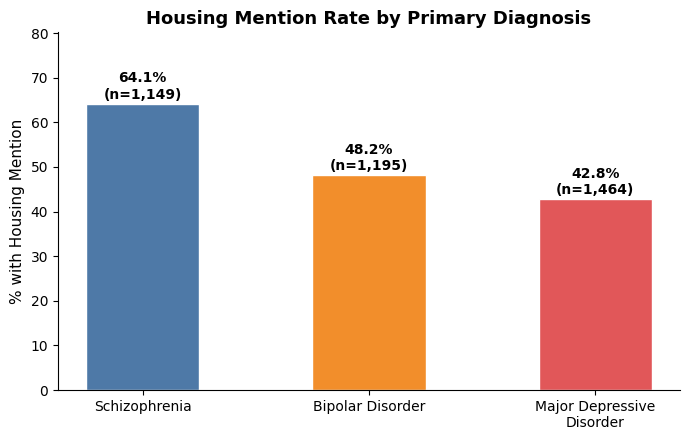

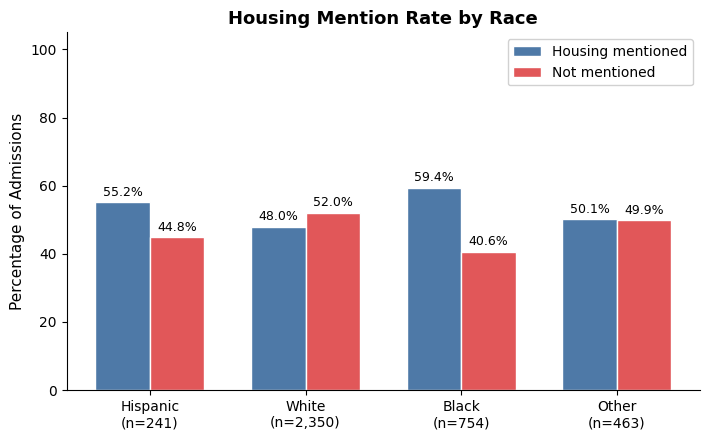

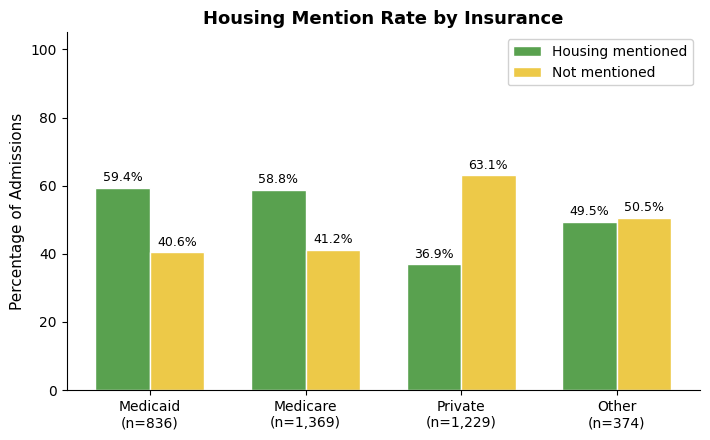

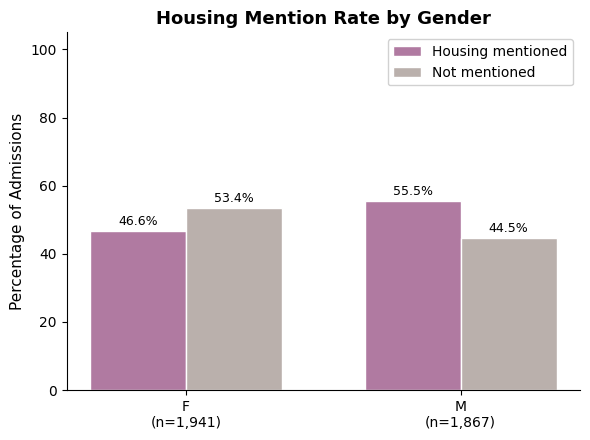

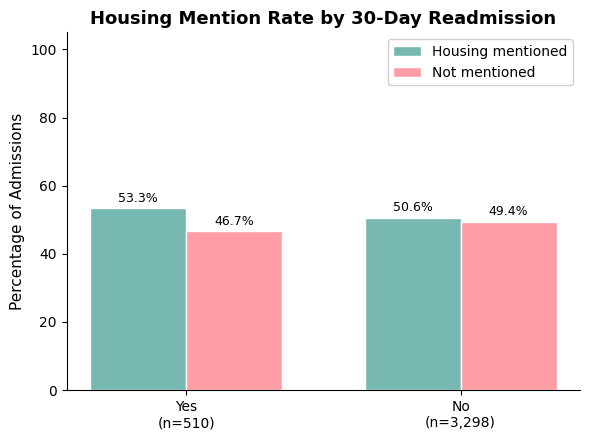

In [24]:
# ========================================================
# Visualizations: Housing Mention Rates by Demographic Group
# ========================================================

def plot_housing_bar(df, column, title, label_order=None, value_map=None, color_yes='#4e79a7', color_no='#e15759'):
    """Grouped bar chart showing housing mention rate by category."""
    s = df[column].copy()
    if value_map is not None:
        s = s.map(value_map).fillna(s)
    groups = label_order if label_order else sorted(s.unique())
    n_list, pct_yes_list, pct_no_list = [], [], []
    for grp in groups:
        mask = s == grp
        n_grp = int(mask.sum())
        n_yes = int((df.loc[mask, 'housing_mention'] == 'yes').sum())
        n_list.append(n_grp)
        pct_yes_list.append(n_yes / n_grp * 100 if n_grp else 0)
        pct_no_list.append((n_grp - n_yes) / n_grp * 100 if n_grp else 0)

    x = range(len(groups))
    width = 0.35
    fig, ax = plt.subplots(figsize=(max(6, len(groups)*1.8), 4.5))
    bars_yes = ax.bar([i - width/2 for i in x], pct_yes_list, width, label='Housing mentioned', color=color_yes, edgecolor='white')
    bars_no  = ax.bar([i + width/2 for i in x], pct_no_list,  width, label='Not mentioned', color=color_no, edgecolor='white')

    ax.set_xticks(list(x))
    ax.set_xticklabels([f'{g}\n(n={n:,})' for g, n in zip(groups, n_list)], fontsize=10)
    ax.set_ylabel('Percentage of Admissions', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylim(0, 105)
    ax.legend(loc='upper right', framealpha=0.9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for bar in bars_yes:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)
    for bar in bars_no:
        h = bar.get_height()
        if h > 0:
            ax.text(bar.get_x() + bar.get_width()/2, h + 1, f'{h:.1f}%', ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

# Overall housing mention — two-column grouped bar (same style as demographic charts)
n_total = len(report_df)
n_yes_all = int((report_df['housing_mention'] == 'yes').sum())
n_no_all = n_total - n_yes_all
pct_yes = n_yes_all / n_total * 100
pct_no = n_no_all / n_total * 100

fig, ax = plt.subplots(figsize=(5, 4.5))
width = 0.4
bars = ax.bar([-width/2, width/2], [pct_yes, pct_no], width,
              color=['#4e79a7', '#e15759'], edgecolor='white')
ax.set_xticks([-width/2, width/2])
ax.set_xticklabels([f'Mentioned\n(n={n_yes_all:,})', f'Not mentioned\n(n={n_no_all:,})'], fontsize=10)
ax.set_ylabel('Percentage of Admissions', fontsize=11)
ax.set_title('Overall Housing Mention Rate\nin SMI Discharge Summaries', fontsize=13, fontweight='bold')
ax.set_ylim(0, 105)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, v in zip(bars, [pct_yes, pct_no]):
    ax.text(bar.get_x() + bar.get_width()/2, v + 1, f'{v:.1f}%',
            ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# By diagnosis
dx_cols = ['schizophrenia', 'bipolar_disorder', 'major_depressive_disorder']
dx_nice = ['Schizophrenia', 'Bipolar Disorder', 'Major Depressive\nDisorder']
dx_pct = []
dx_n = []
for dx in dx_cols:
    sub = report_df.loc[report_df[dx] == 1]
    dx_n.append(len(sub))
    dx_pct.append((sub['housing_mention'] == 'yes').mean() * 100 if len(sub) else 0)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(dx_nice, dx_pct, color=['#4e79a7', '#f28e2b', '#e15759'], edgecolor='white', width=0.5)
for bar, v, n in zip(bars, dx_pct, dx_n):
    ax.text(bar.get_x() + bar.get_width()/2, v + 0.5, f'{v:.1f}%\n(n={n:,})',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_ylabel('% with Housing Mention', fontsize=11)
ax.set_title('Housing Mention Rate by Primary Diagnosis', fontsize=13, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0, max(dx_pct) * 1.25 if dx_pct else 100)
plt.tight_layout()
plt.show()

# By race, insurance, gender, readmission
plot_housing_bar(report_df, 'race_category',
                 'Housing Mention Rate by Race',
                 label_order=['Hispanic', 'White', 'Black', 'Other'])

plot_housing_bar(report_df, 'insurance_category',
                 'Housing Mention Rate by Insurance',
                 label_order=['Medicaid', 'Medicare', 'Private', 'Other'],
                 color_yes='#59a14f', color_no='#edc948')

plot_housing_bar(report_df, 'gender',
                 'Housing Mention Rate by Gender',
                 color_yes='#b07aa1', color_no='#bab0ac')

plot_housing_bar(report_df, 'readmission_30day',
                 'Housing Mention Rate by 30-Day Readmission',
                 label_order=['Yes', 'No'],
                 value_map={1: 'Yes', 0: 'No'},
                 color_yes='#76b7b2', color_no='#ff9da7')

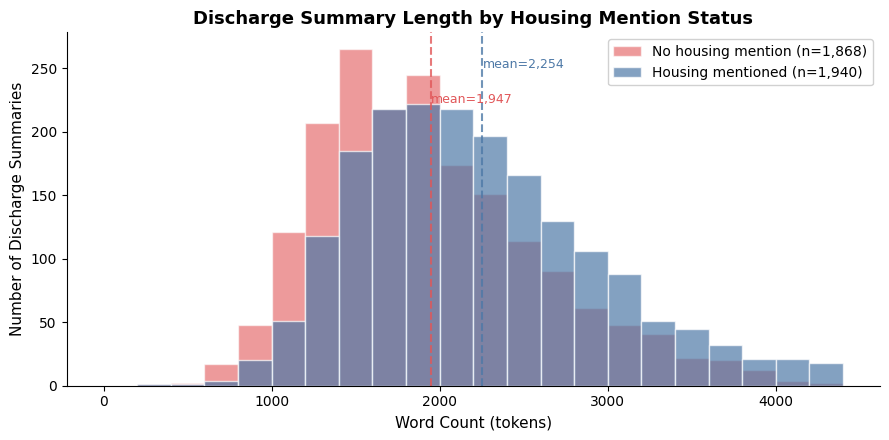

In [25]:
# Token count distributions: housing mention vs. no mention
report_df['n_tokens'] = report_df['discharge_text'].astype(str).str.split().apply(len)
tokens_yes = report_df.loc[report_df['housing_mention'] == 'yes', 'n_tokens']
tokens_no  = report_df.loc[report_df['housing_mention'] == 'no',  'n_tokens']

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = range(0, int(report_df['n_tokens'].quantile(0.99)) + 200, 200)
ax.hist(tokens_no, bins=bins, alpha=0.6, color='#e15759', label=f'No housing mention (n={len(tokens_no):,})', edgecolor='white')
ax.hist(tokens_yes, bins=bins, alpha=0.7, color='#4e79a7', label=f'Housing mentioned (n={len(tokens_yes):,})', edgecolor='white')
ax.set_xlabel('Word Count (tokens)', fontsize=11)
ax.set_ylabel('Number of Discharge Summaries', fontsize=11)
ax.set_title('Discharge Summary Length by Housing Mention Status', fontsize=13, fontweight='bold')
ax.legend(fontsize=10, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.axvline(tokens_yes.mean(), color='#4e79a7', linestyle='--', linewidth=1.5, alpha=0.8)
ax.axvline(tokens_no.mean(), color='#e15759', linestyle='--', linewidth=1.5, alpha=0.8)
ax.text(tokens_yes.mean(), ax.get_ylim()[1]*0.9, f'mean={tokens_yes.mean():,.0f}', color='#4e79a7', fontsize=9, ha='left')
ax.text(tokens_no.mean(), ax.get_ylim()[1]*0.8, f'mean={tokens_no.mean():,.0f}', color='#e15759', fontsize=9, ha='left')
plt.tight_layout()
plt.show()

## Summary of Findings

### What We Did

Starting from 546,028 MIMIC-IV admissions, we built an admission-level dataset, filtered to admissions whose primary diagnosis was schizophrenia, bipolar disorder, or severe/recurrent MDD, removed non-community discharges, and merged in cleaned MIMIC-IV-Note discharge summaries. Before applying our 20-keyword housing search, we validated it against MIMIC-III-Labeled-SDOH. The result is a cohort of **3,808 admissions across 2,859 unique patients**, each with a discharge summary and a housing-mention label.

### What We Found

1. **Overall:** 50.9% of SMI discharge summaries contain a housing mention (1,940 of 3,808). Because keyword recall on the validation set is only 0.39, this is a lower bound on the true rate.

2. **By primary diagnosis:** 64.1% of schizophrenia discharge summaries mention housing, vs. 48.2% of bipolar disorder summaries and 42.8% of major depressive disorder summaries — a 21-point gap from highest to lowest.

3. **By insurance type:** 59.4% of Medicaid discharge summaries mention housing, vs. 58.8% of Medicare, 49.5% of Other, and 36.9% of Private — a 22-point gap between Medicaid and Private, the largest demographic difference observed.

4. **By race:** 59.4% of Black patients' discharge summaries mention housing, vs. 55.2% of Hispanic, 50.1% of Other, and 48.0% of White.

5. **By gender:** 55.5% of male patients' discharge summaries mention housing, vs. 46.6% of female patients'.

6. **By 30-day readmission status:** 53.3% of discharge summaries for patients readmitted within 30 days mention housing, vs. 50.6% for patients not readmitted — a 2.7-point difference.

7. **Note length:** discharge summaries that mention housing average 2,254 words; those without a mention average 1,947 — a difference of about 300 words.

### How to Read These Numbers

Two caveats apply throughout. First, our headline mention rate is a lower bound — keyword recall is 0.39, so the keyword search misses a substantial fraction of real housing discussions, and the gaps between groups would shift if we caught those mentions. Second, all of these are descriptive associations from a single institution. We cannot make causal claims, and we cannot generalize to hospitals with different populations or documentation cultures.

### Limitations

- **Keyword search imperfections.** The search misses housing discussions phrased in unfamiliar ways and can flag irrelevant matches. Errors on full discharge summaries may differ from errors on the isolated sentences used for validation.
- **Single institution.** All findings come from Beth Israel Deaconess Medical Center (via MIMIC-IV).

### Next Steps

In Milestone 3 we will fine-tune a ClinicalBERT model on the MIMIC-III-Labeled-SDOH labels, apply it to our discharge summaries, and compare it against the keyword baseline. The model should catch mentions the keyword search misses and reduce false positives, giving us a more accurate picture of documentation rates and a stronger basis for the disparity comparisons.

In [26]:
# Save df_final to CSV in Google Drive data directory
output_path = os.path.join(base_path, 'df_final.csv')
df_final.to_csv(output_path, index=False)
print(f'Saved df_final to: {output_path}')
print(f'Rows: {len(df_final):,}, Columns: {df_final.shape[1]:,}')

Saved df_final to: /content/drive/MyDrive/AC209b-project-data/df_final.csv
Rows: 3,808, Columns: 33
